# Miscancelaneous computations

## Computing OTFS

In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import numpy as np
import pandas as pd
from matplotlib.patches import Circle
import os
import myfunctions
import h5py
D = 17.5e-3  # [m]
wl = 632.8e-9  # [m]
pad = 2
dx = 3.928571e-06

In [2]:
with h5py.File("dataInputs/ao_ipsf_test_1.h5", 'r') as temp:
            key = list(temp.keys())
            ipsf = temp[key[0]][()][:]

with h5py.File("dataInputs/ipsf_difflim.h5", 'r') as temp:
            ipsf_difflim = temp[list(temp.keys())[0]][()]

padded_ipsf = myfunctions.pad_center(ipsf, pad)
padded_ipsf_difflim = myfunctions.pad_center(ipsf_difflim, pad)
OTF_diff_lim = np.abs(myfunctions.otf_from_psf(padded_ipsf_difflim))


N = ipsf_difflim.shape[1]*pad
fc = D / wl
freq = np.fft.fftshift(np.fft.fftfreq(N, d=dx))
freq_n = np.abs(freq) / fc
NU_X, NU_Y = np.meshgrid(freq_n, freq_n)
nu_n_grid = np.sqrt(NU_X**2 + NU_Y**2)
# FREQ_MASK = np.abs(freq) < fc
FREQ_MASK = nu_n_grid < 1


OTF_diff_lim = np.abs(myfunctions.otf_from_psf(padded_ipsf_difflim))
OTF_tel = myfunctions.telescope_otf(nu_n_grid)
OTF_aliasing = OTF_diff_lim - OTF_tel

# OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:] - OTF_aliasing)*FREQ_MASK
# OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:])*FREQ_MASK
OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:])


In [ ]:
therandom = np.random.randint(0, OTFs.shape[0])
print(therandom)
plt.figure(figsize=(10, 8))
plt.plot(freq, OTF_tel[N//2, :], ".-b", label="Theoretical diffraction-limited OTF")
plt.plot(freq, OTF_diff_lim[N//2, :], "k", linestyle="dotted", label="Diffraction-limited OTF\nfrom simulated PSF with aliasing")
plt.plot(freq, OTF_aliasing[N//2, :],"--.",label = "Aliasing OTF")
plt.plot(freq, OTFs[therandom,N//2, :],"--k", label="Measured OTF without aliasing")
plt.plot(freq, OTF_diff_lim[N//2, :]-OTF_aliasing[N//2, :], "--.k", label="Diffraction-limited OTF\nfrom simulated PSF without aliasing")
plt.vlines([-fc, fc], 0, 1, "k", linestyles=[(0, (1, 10))], label = r"$\pm$ cutoff frequency")
plt.title(f"Diffraction limited and randomly\nselected OTFs (N°{therandom})", fontsize = 22)
plt.xlabel("Angular frequency [cycles/meter]", fontsize=18)
plt.ylabel("OTF", fontsize=18)
plt.xlim([-fc * 1.2, fc * 1.2])
plt.ylim([0, 1])
plt.xticks(fontsize=18*.8)
plt.yticks(fontsize=18*.8)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=18)
plt.tight_layout()

In [3]:
with h5py.File("dataInputs/ao_iOTF_test_"+str(1)+".h5", "w") as f:
    f.create_dataset("iOTF", data=OTFs)

In [4]:
with h5py.File("dataInputs/ao_ipsf_val_1.h5", 'r') as temp:
            key = list(temp.keys())
            ipsf = temp[key[0]][()][:]

padded_ipsf = myfunctions.pad_center(ipsf, pad)

# OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:] - OTF_aliasing)*FREQ_MASK
OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:] )

with h5py.File("dataInputs/ao_iOTF_val_"+str(1)+".h5", "w") as f:
    f.create_dataset("iOTF", data=OTFs)

In [5]:
with h5py.File("dataInputs/ao_ipsf_train_1.h5", 'r') as temp:
            key = list(temp.keys())
            ipsf = temp[key[0]][()][:]

padded_ipsf = myfunctions.pad_center(ipsf, pad)

# OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:] - OTF_aliasing)*FREQ_MASK
OTFs = (np.abs(myfunctions.otf_from_psf(padded_ipsf))[...,:,:])

with h5py.File("dataInputs/ao_iOTF_train_"+str(1)+".h5", "w") as f:
    f.create_dataset("iOTF", data=OTFs)

In [3]:
with h5py.File("output_prep/ao_intensity_map_test_1.h5", 'r') as temp:
            key = list(temp.keys())
            ipsf = temp[key[0]][()][:]

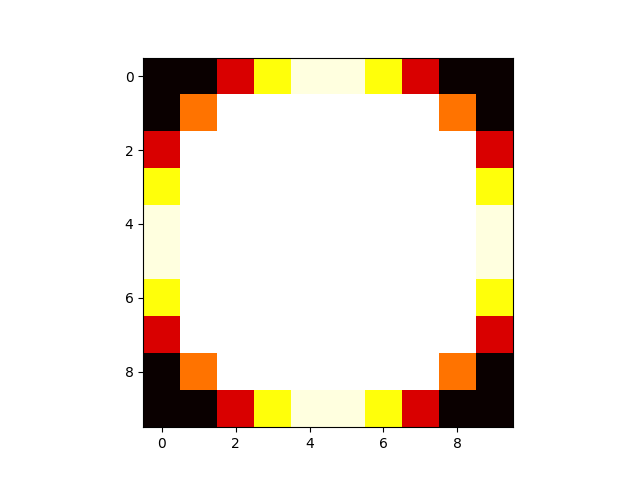

In [ ]:
plt.figure()
plt.imshow(ipsf[8,:, :], cmap="hot")